# Версия 3, част 1 — коя е тази единица? (crop класификатор)

**Защо започваме наново.** Версия 2 гледаше целия screenshot (1280×720) и трябваше да каже кои от 48 единици
има. Една единица заема около 50×60 пиксела — под 0.5% от картинката. Моделът трябва едновременно да *намери*
малките фигурки и да ги *разпознае*, а освен това не може да брои: „двама Footman“ и „един Footman“ дават
един и същ етикет. Затова грешеше често и изглеждаше, че „гадае“.

**Новият план** разделя задачата на две прости части:

1. **Къде има единици?** — детектор, който дава по една рамка за всяка единица (така броят е верен).
2. **Коя е тази единица?** — класификатор, който гледа *само* изрязаната рамка и избира 1 от 48 (softmax),
   точно като Lesson 1 / Версия 1, но с чисти изображения от самата игра.

Този notebook прави част 2. Данните са solo снимките (`data/single_units`): на всяка има **един тип**,
1–3 копия. JASS скриптът ги поставя на известни места спрямо камерата, затова можем да изчислим къде са
на екрана и да изрежем всяко копие — без ръчно маркиране.

In [1]:
from fastai.vision.all import *

BASE = Path('data/single_units')
CROPS = Path('data/unit_crops')
rows = pd.read_csv(BASE/'labels.csv')
excluded = pd.read_csv(BASE/'excluded.csv')
rows = rows[rows['split'].isin(['train','valid','test'])]
rows.groupby(['map','split']).size()

C:\Users\bobia\Desktop\warcraft_p\warcraft3-classifier\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


map            split
single-train1  train    1369
single-train2  train     923
single-train3  train     499
single-valid1  valid     167
dtype: int64

## Къде е всяка единица на екрана

`dataset_trigger_single.j` поставя камерата над точка (cx, cy) с ъгъл 304° (гледа надолу под 56°), разстояние
`zoom`, и слага копията на отместване `offsetx + i·340`, `offsety` от тази точка. С обикновена перспективна
проекция пресмятаме пикселите. Трите числа `F`, `CX`, `CY` са измерени от няколко снимки
(F = фокусно разстояние в пиксели, CX/CY = къде на екрана се вижда точката на камерата).
Рамката е по-висока нагоре, за да хване и летящите единици.

In [2]:
F, CX, CY = 908, 630, 286
COS, SIN = np.cos(np.radians(56)), np.sin(np.radians(56))

def unit_boxes(r):
    "Screen boxes (left, top, right, bottom) of every copy in a solo shot."
    offsetx = (r.position % 3 - 1) * 220.0          # same formulas as in the JASS script
    offsety = (r.position // 3 - 1) * 140.0 - 70.0
    boxes = []
    for i in range(r.copies):
        x = offsetx + (i - (r.copies - 1) / 2) * 340
        y = offsety
        depth = r.zoom + y * COS
        sx, sy, scale = CX + F * x / depth, CY - F * y * SIN / depth, F / depth
        boxes.append((sx - 175*scale, sy - 320*scale, sx + 175*scale, sy + 145*scale))
    return boxes

## Изрязване

Всяко копие става отделна малка снимка с етикета на solo снимката. Map 2 има 761 кадъра с изключен текст
„No clear capture area“ (y ≈ 415–431). За crop-овете пазим копията, чиято рамка не стига до този текст —
така връщаме голяма част от тези кадри, без текстът да влиза в данните. Другите изключени кадри остават изключени.

In [3]:
WARNING_TEXT = (223, 405, 571, 441)
warning = set(excluded.loc[excluded['reason'].str.contains('warning text'), 'fname'])
bad = set(excluded['fname']) - warning

def overlaps(a, b): return a[0] < b[2] and b[0] < a[2] and a[1] < b[3] and b[1] < a[3]

(CROPS/'images').mkdir(parents=True, exist_ok=True)
crops = []
for r in rows.itertuples():
    if r.fname in bad: continue
    img = None
    for i, box in enumerate(unit_boxes(r)):
        if r.fname in warning and overlaps(box, WARNING_TEXT): continue
        name = f'{Path(r.fname).stem}_{i}.jpg'
        if not (CROPS/'images'/name).exists():
            if img is None: img = Image.open(BASE/'screens'/r.fname)
            img.crop(tuple(round(v) for v in box)).save(CROPS/'images'/name, quality=95)
        crops.append((name, r.labels, r.map, r.split))
crops = pd.DataFrame(crops, columns=['fname','label','map','split'])
crops.to_csv(CROPS/'crops.csv', index=False)
print(len(crops), 'crops'); crops.groupby(['map','split']).size()

3967 crops


map            split
single-train1  train    2520
single-train2  train     783
single-train3  train     497
single-valid1  valid     167
dtype: int64

In [4]:
crops.groupby('split')['label'].value_counts().groupby('split').agg(['min','max','count'])

,min,max,count
split,,,
train,76,84,48
valid,3,4,48


## DataBlock и аугментация

- `CategoryBlock` — точно една единица на crop, softmax, както Версия 1.
- Validation = цяла карта, която моделът не е виждал (`single-valid1`), не случайни кадри.
- Аугментация, подходяща за играта: огледален образ (единиците гледат във всички посоки), лек zoom и
  отместване (детекторът няма да реже точно като нашата формула), промяна на светлината (ден/нощ).
  Без голямо въртене — камерата в Warcraft III винаги е под същия ъгъл.

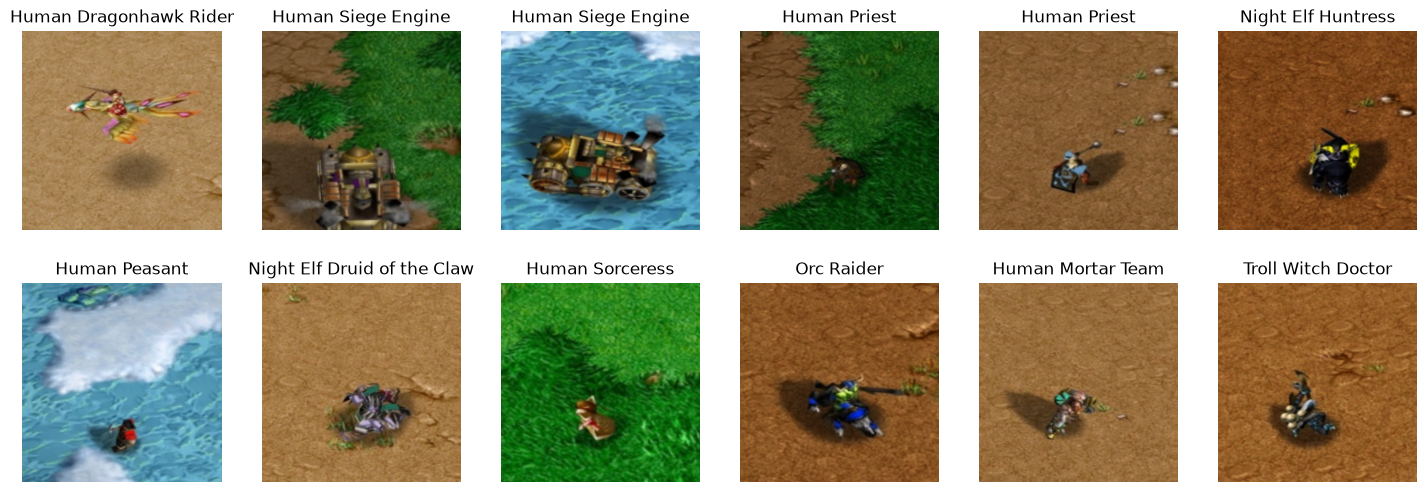

In [5]:
df = crops[crops['split'].isin(['train','valid'])].copy()
df['is_valid'] = df['split'].eq('valid')
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_x=ColReader('fname', pref=CROPS/'images'), get_y=ColReader('label'),
    splitter=ColSplitter('is_valid'),
    item_tfms=Resize(224, method='squish'),
    batch_tfms=aug_transforms(max_rotate=5, max_zoom=1.25, max_lighting=0.3, max_warp=0)
).dataloaders(df, bs=32, num_workers=0)
dls.show_batch(max_n=12, nrows=2)

## Обучение

`convnext_tiny.fb_in22k` — същият модел, който беше най-добър във Версия 1. `fine_tune`: първо само новата
глава, после целият модел.
На GTX 1080 Ti обучението понякога внезапно дава `nan` в случаен batch (в епоха 1, 2 или 5 — различно
при всяко пускане, и с по-малък learning rate). Затова, както във Версия 2: `SaveModelCallback` пази
най-добрата епоха по `valid_loss`, а `TerminateOnNaNCallback` спира, ако се появи `nan`.
`to_fp16()` (mixed precision) прави обучението по-бързо и по-малко памет.

In [6]:
set_seed(42)
learn = vision_learner(dls, 'convnext_tiny.fb_in22k', metrics=[accuracy, error_rate], path=CROPS).to_fp16()
learn.fine_tune(8, base_lr=2e-3, cbs=[SaveModelCallback(monitor='valid_loss', fname='best'),
                                     TerminateOnNaNCallback()])
learn.load('best')
learn.validate()

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.009708,0.698299,0.784431,0.215569,01:55


Better model found at epoch 0 with valid_loss value: 0.6982990503311157.


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.476272,0.351094,0.922156,0.077844,02:10
1,0.243456,0.123839,0.970060,0.029940,02:09
2,0.119764,0.105140,0.976048,0.023952,02:10
3,0.077872,0.072232,0.976048,0.023952,02:34
4,0.041028,0.053215,0.988024,0.011976,02:15
5,0.034232,0.049890,0.976048,0.023952,02:06
6,0.020008,0.039094,0.988024,0.011976,02:07
7,0.016378,0.043323,0.976048,0.023952,02:08


Better model found at epoch 0 with valid_loss value: 0.35109442472457886.


Better model found at epoch 1 with valid_loss value: 0.12383930385112762.


...

Better model found at epoch 4 with valid_loss value: 0.053214676678180695.


Better model found at epoch 5 with valid_loss value: 0.04989034682512283.


Better model found at epoch 6 with valid_loss value: 0.03909377008676529.


C:\Users\bobia\Desktop\warcraft_p\warcraft3-classifier\.venv\Lib\site-packages\fastai\learner.py:68: UserWarning: Saved file doesn't contain an optimizer state.
  elif with_opt: warn("Saved file doesn't contain an optimizer state.")


[0.03909377008676529, 0.9880239367485046, 0.011976048350334167]

## Резултати на непознатата карта

In [7]:
interp = ClassificationInterpretation.from_learner(learn)
interp.most_confused(min_val=1)

[('Human Priest', 'Human Sorceress', np.int64(1)),
 ('Night Elf Hippogryph Rider', 'Human Gryphon Rider', np.int64(1))]

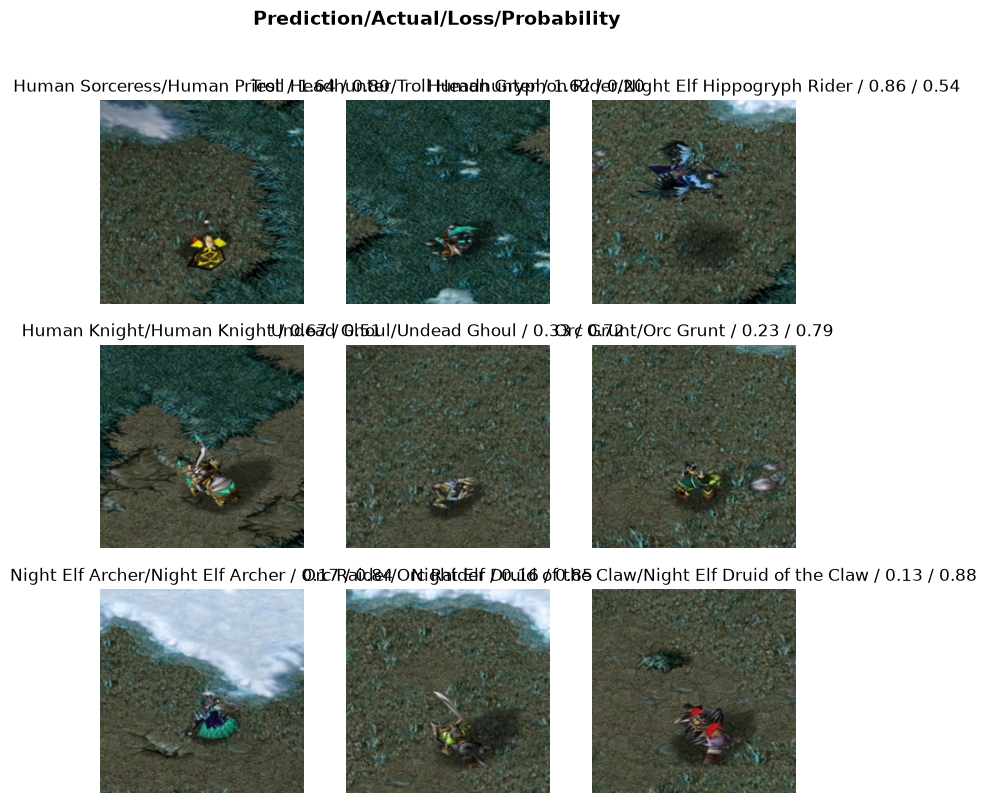

In [8]:
interp.plot_top_losses(9, nrows=3)

In [9]:
learn.export('unit_classifier.pkl')

## Какво следва

- Ако на непознатата карта сме над ~97%, класификаторът е готов; слабите места се оправят с повече solo
  снимки на объркваните единици (`most_confused`).
- Част 1: детектор, който намира рамките в целия screenshot. Рамките за обучението идват от същата формула
  `unit_boxes`, затова solo снимките стават и данни за детектора.
- Цял screenshot е напълно верен, ако детекторът намери всички единици **и** класификаторът познае всяка.
  При 98% на единица и 4 единици на снимка това е около 0.98⁴ ≈ 92%.